# Optimization solutions and their constraints

Family 29. QuadraticProgram minimizes one-half x-transpose Q x plus c-transpose x. Bounds are free by default. Solver status and primal feasibility accompany each solution; local nonlinear success is not a global certificate.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 29: array QP, conic budget, integer LP and callback optimization."""
import numpy as np
from convexity.math import optimization as opt

problem = opt.QuadraticProgram([-1., -2.], quadratic=np.eye(2), equality=[[1., 1.]], target=[1.], lower_bounds=0.)
result = opt.solve(problem)
print('QP:', result.solution, result.objective, dict(result.duals))
cone = opt.SecondOrderCone(np.eye(2), [0., 0.], [0., 0.], 1.)
print('Conic:', opt.solve(opt.QuadraticProgram([-3., -4.], cones=(cone,))).solution)
integer = opt.QuadraticProgram([-3., -2.], inequality=[[2., 1.]], upper=[3.], lower_bounds=0,
                               upper_bounds=[1, 3], domains=['binary', 'integer'])
print('Integer LP:', opt.solve(integer, opt.ConvexSolver('SCIPY')).solution)
print('Nonlinear:', opt.solve(opt.NonlinearProblem(lambda x: (x[0]-2)**2, [0.], upper_bounds=1.)).solution)


QP: [5.46631385e-05 9.99945337e-01] -1.4999999970114861 {'equality': array([1.00005467]), 'lower_bounds': array([1.09328995e-04, 2.72097713e-09])}
Conic: [0.6 0.8]
Integer LP: [0. 3.]
Nonlinear: [1.]


## A constrained quadratic allocation path

Increasing the variance penalty changes the allocation toward the lower-variance asset. At a bound, the active set changes. The equality constraint fixes total invested weight at one.

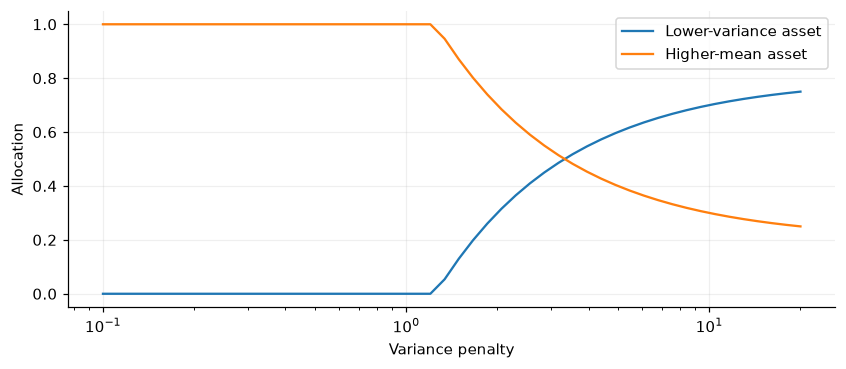

,Asset 1,Asset 2
0.100000,4.082710e-09,1.000000
0.294848,1.864723e-08,1.000000
0.869353,3.962356e-08,1.000000
2.563267,4.098729e-01,0.590127
7.557738,6.676853e-01,0.332315


In [3]:
penalties = np.geomspace(.1, 20, 50)
solutions = []
for penalty in penalties:
    p = opt.QuadraticProgram([-.05, -.1], quadratic=penalty*np.diag([.01, .04]),
                              equality=[[1., 1.]], target=[1.], lower_bounds=0.)
    solutions.append(opt.solve(p).solution)
solutions = np.array(solutions)
plt.semilogx(penalties, solutions[:, 0], label='Lower-variance asset')
plt.semilogx(penalties, solutions[:, 1], label='Higher-mean asset')
plt.xlabel('Variance penalty'); plt.ylabel('Allocation'); plt.legend(); plt.show()
display(pd.DataFrame(solutions[::10], columns=['Asset 1', 'Asset 2'], index=penalties[::10]))

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.